# ICA for EEG
**reference** https://mne.tools/stable/auto_tutorials/preprocessing/40_artifact_correction_ica.html

**Include Library**

In [1]:
# import require library for preprocess
import mne
import numpy as np
from mne.channels import make_standard_montage
import matplotlib.pyplot as plt
from mne.datasets import eegbci
import scipy
import pickle
import seaborn as sns

# import require library for classification
from sklearn.svm import SVC # SVM library
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis # LDA library
from sklearn.neighbors import KNeighborsClassifier # KNN library
from sklearn.model_selection import train_test_split, GridSearchCV, KFold

from sklearn.metrics import classification_report,confusion_matrix # Result representation
from os import listdir

from mne.preprocessing import ICA

**Get all EEG data**

In [2]:
subject = 's009'

folder_path = 'D:\\MTP_task\\MTP_eeg\\' + subject + '\\'
files = listdir(folder_path)
raw_ME = [0]*(int(len(files)/2))
raw_MI = [0]*(int(len(files)/2))
j,k = 0,0
for i in range(len(files)):
    if (i+1) % 2 == 0:
        print("Reading file MI: " + files[i])
        raw_MI[j] = mne.io.read_raw_bdf(folder_path + files[i], preload=True, verbose=False)
        j += 1
    else:
        print("Reading file ME: " + files[i])
        raw_ME[k] = mne.io.read_raw_bdf(folder_path + files[i], preload=True, verbose=False)
        k += 1

raw_ME_all= mne.concatenate_raws(raw_ME)
raw_MI_all= mne.concatenate_raws(raw_MI)

Reading file ME: s009_MTP_block01.bdf
Reading file MI: s009_MTP_block02.bdf
Reading file ME: s009_MTP_block03.bdf
Reading file MI: s009_MTP_block04.bdf
Reading file ME: s009_MTP_block05.bdf
Reading file MI: s009_MTP_block06.bdf
Reading file ME: s009_MTP_block07.bdf
Reading file MI: s009_MTP_block08.bdf
Reading file ME: s009_MTP_block09.bdf
Reading file MI: s009_MTP_block10.bdf
Reading file ME: s009_MTP_block11.bdf
Reading file MI: s009_MTP_block12.bdf


In [3]:
raw_ME_all

<RawBDF | s009_MTP_block01.bdf, 73 x 1255936 (2453.0 s), ~699.5 MiB, data loaded>

In [4]:
def mark_channels(raw):
    raw.set_channel_types({ch: 'eeg' for ch in raw.ch_names[:64]})

    # EOG channels (by name)
    eog_names = ['EXG3', 'EXG4', 'EXG5', 'EXG6']
    raw.set_channel_types({ch: 'eog' for ch in eog_names if ch in raw.ch_names})

    # # misc channels (by name)
    # misc_names = ['EXG1', 'EXG2']
    # raw.set_channel_types({ch: 'misc' for ch in misc_names if ch in raw.ch_names})

    return raw

raw_ME_all = mark_channels(raw_ME_all)
raw_MI_all = mark_channels(raw_MI_all)


In [5]:
montage = make_standard_montage("biosemi64")
raw_ME_all.set_montage(montage, on_missing='ignore')
raw_MI_all.set_montage(montage, on_missing='ignore')

#Band pass and notch filter
def preprocess_raw(raw):
    raw_filter = raw.copy().filter(l_freq=0.1, h_freq=50, verbose = False, fir_design="firwin", picks='eeg')
    raw_reref = mne.set_eeg_reference(raw_filter, ref_channels=['EXG1', 'EXG2'])
    raw = raw_reref[0].copy().notch_filter(freqs=50)
    return raw

raw_ME_all = preprocess_raw(raw_ME_all)
raw_MI_all = preprocess_raw(raw_MI_all)

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.
Filtering raw data in 6 contiguous segments
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 3381 samples (6.604 s)

Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutof

In [6]:
event_dict =  {'Number 1': 101,
    'Number 2': 102,
    'Number 3': 103,
    'Number 4': 104,
    }

events_ME = mne.find_events(raw_ME_all, shortest_event = 0, verbose = False)
Epochs_ME = mne.Epochs(raw_ME_all, events_ME, 
    tmin= -2.5,  
    tmax= 7.0,    
    event_id=event_dict,
    preload = True,
    event_repeated='drop',
    baseline= None,
    verbose=False
)

events_MI = mne.find_events(raw_MI_all, shortest_event = 0, verbose = False) 
Epochs_MI = mne.Epochs(raw_MI_all, events_MI, 
    tmin= -2.5,
    tmax= 7.0,
    event_id=event_dict,
    preload = True,
    event_repeated='drop',
    baseline= None,
    verbose=False
)

All_Epochs = mne.concatenate_epochs([Epochs_ME, Epochs_MI]) # List of Epochs instances to concatenate (in that order).


C:\Users\pipo_\AppData\Local\Temp\ipykernel_26356\3664898864.py:29: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  All_Epochs = mne.concatenate_epochs([Epochs_ME, Epochs_MI]) # List of Epochs instances to concatenate (in that order).


Not setting metadata
480 matching events found
No baseline correction applied


# ICA with Epoch data

In [7]:
# All_Epochs_for_ICA_true = All_Epochs.copy().pick_channels(ch_names= All_Epochs.ch_names[0:64])
# All_Epochs_for_ICA = All_Epochs.copy().filter(l_freq=1, h_freq=50, verbose=False, fir_design="firwin", picks='eeg').pick_channels(ch_names= All_Epochs.ch_names[0:64])

In [8]:
All_Epochs_for_ICA = All_Epochs.copy().filter(l_freq=1, h_freq=50, verbose=False, fir_design="firwin", picks='eeg').pick_channels(ch_names= All_Epochs.ch_names[0:64])

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


In [9]:
# All_Epochs_for_ICA.plot()

In [10]:
ica = ICA(n_components=64, max_iter='auto', random_state=97, method='infomax', verbose=False)
ica.fit(All_Epochs_for_ICA)
ica 

Fitting ICA to data using 64 channels (please be patient, this may take a while)


Selecting by number: 64 components
Computing Infomax ICA
Fitting ICA took 1760.3s.


Method,infomax
Fit parameters,extended=Falsemax_iter=500
Fit,500 iterations on epochs (2335200 samples)
ICA components,64
Available PCA components,64
Channel types,eeg
ICA components marked for exclusion,—


In [11]:
from mne_icalabel import label_components
ic_labels = label_components(All_Epochs_for_ICA, ica, method="iclabel")
ic_labels

C:\Users\pipo_\AppData\Local\Temp\ipykernel_26356\626239694.py:2: RuntimeWarning: The provided Epochs instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for Raw and Epochs instances).
  ic_labels = label_components(All_Epochs_for_ICA, ica, method="iclabel")
C:\Users\pipo_\AppData\Local\Temp\ipykernel_26356\626239694.py:2: RuntimeWarning: The provided ICA instance was fitted with a 'infomax' algorithm. ICLabel was designed with extended infomax ICA decompositions. To use the extended infomax algorithm, use the 'mne.preprocessing.ICA' instance with the arguments 'ICA(method='infomax', fit_params=dict(extended=True))' (scikit-learn) or 'ICA(method='picard', fit_params=dict(ortho=False, extended=True))' (python-picard).
  ic_labels = label_components(All_Epochs_for_ICA, ica, method="iclabel")


{'y_pred_proba': array([0.9741081 , 0.6081328 , 0.45105204, 0.99997747, 0.97791487,
        0.60494304, 0.33012557, 0.43141997, 0.36081374, 0.98632956,
        0.6759634 , 0.9988671 , 0.9983188 , 0.8842962 , 0.3558005 ,
        0.9926761 , 0.986107  , 0.33488464, 0.24899945, 0.5184976 ,
        0.99776536, 0.96049386, 0.9964062 , 0.3704785 , 0.98917794,
        0.74623483, 0.39836156, 0.99442065, 0.8175308 , 0.8864792 ,
        0.9406829 , 0.9562278 , 0.49785617, 0.5017712 , 0.9820434 ,
        0.2950843 , 0.84022135, 0.47643888, 0.38264734, 0.72923744,
        0.97009856, 0.65361625, 0.70269114, 0.5181209 , 0.7668991 ,
        0.47640413, 0.97504616, 0.42382944, 0.5635755 , 0.77309513,
        0.46884024, 0.7021125 , 0.36327875, 0.68551505, 0.43588585,
        0.5088864 , 0.6274256 , 0.66947716, 0.8658119 , 0.6363965 ,
        0.6863089 , 0.5321206 , 0.46913543, 0.4950846 ], dtype=float32),
 'labels': ['eye blink',
  'eye blink',
  'other',
  'brain',
  'brain',
  'eye blink',
  'brai

In [12]:
keep_components = ["brain", "other"]

exclude_idx = []

for idx, label in enumerate(ic_labels['labels']):
    if label not in keep_components:
        exclude_idx.append(idx)
    # if idx <= 5 and label == "other": #remove suspect "other" components
    #     exclude_idx.append(idx)
        

if exclude_idx == []:
    exclude_idx = [0]
print(exclude_idx)

[0, 1, 5, 8, 9, 14, 17, 18, 19, 24, 25, 28, 31, 32, 34, 40, 43, 46, 47, 50, 52, 54, 58, 59, 62]


    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 pro

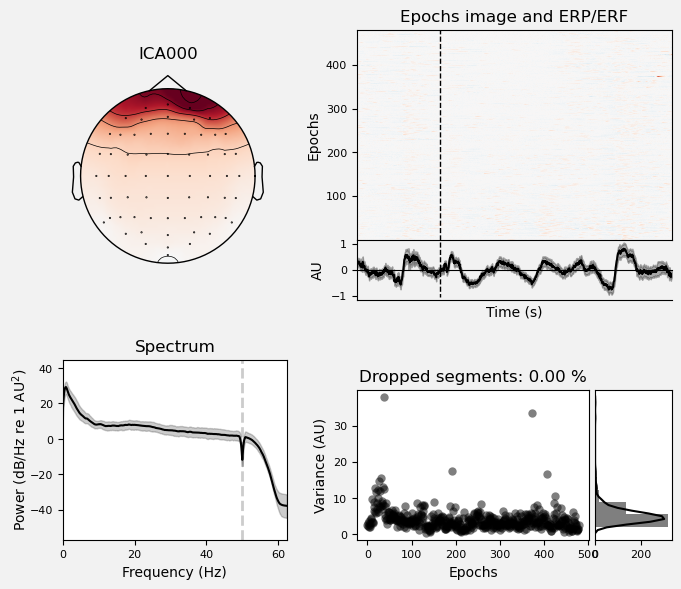

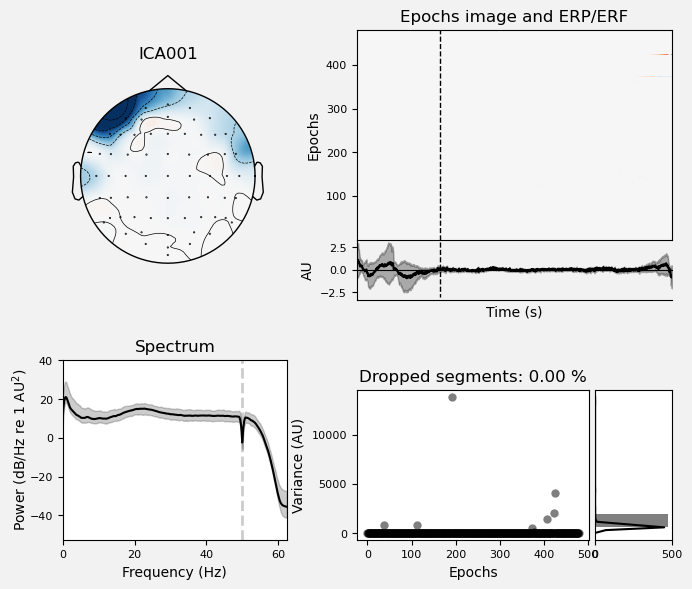

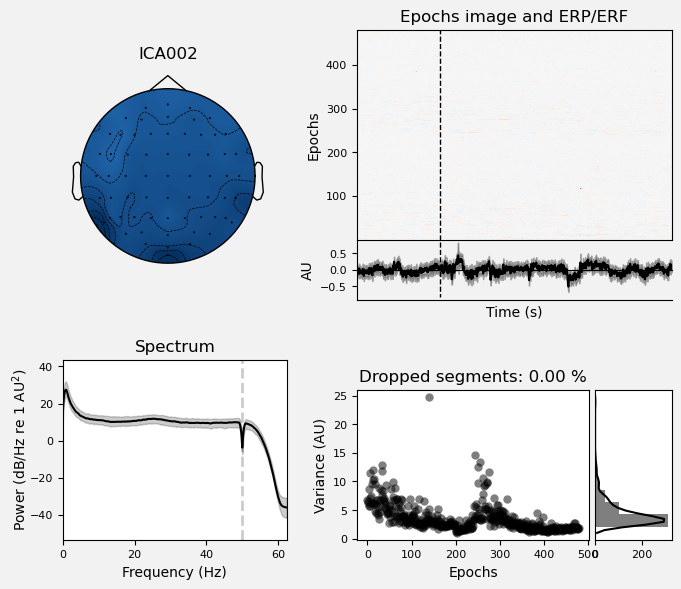

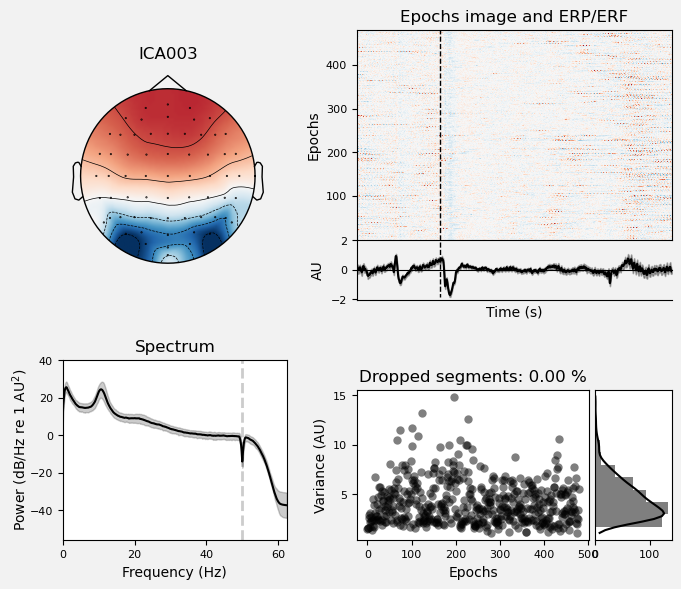

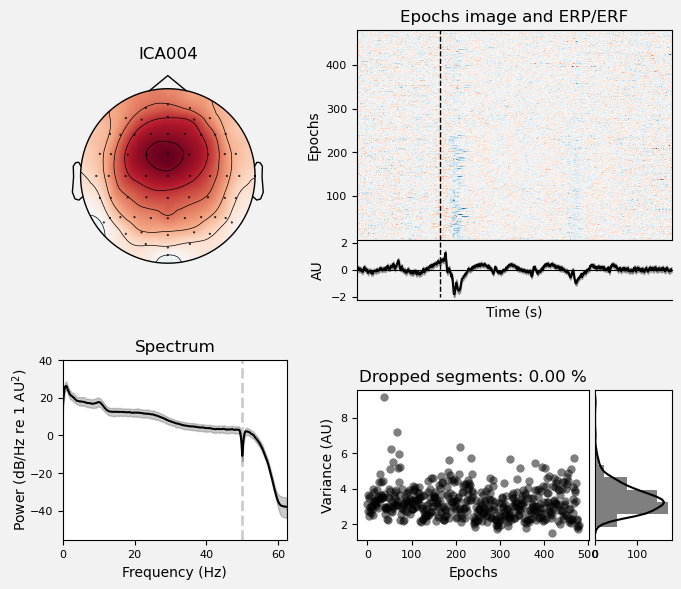

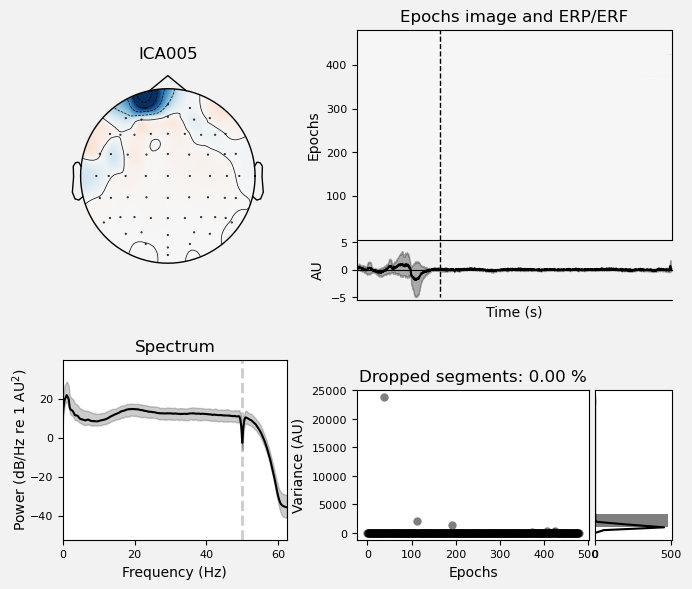

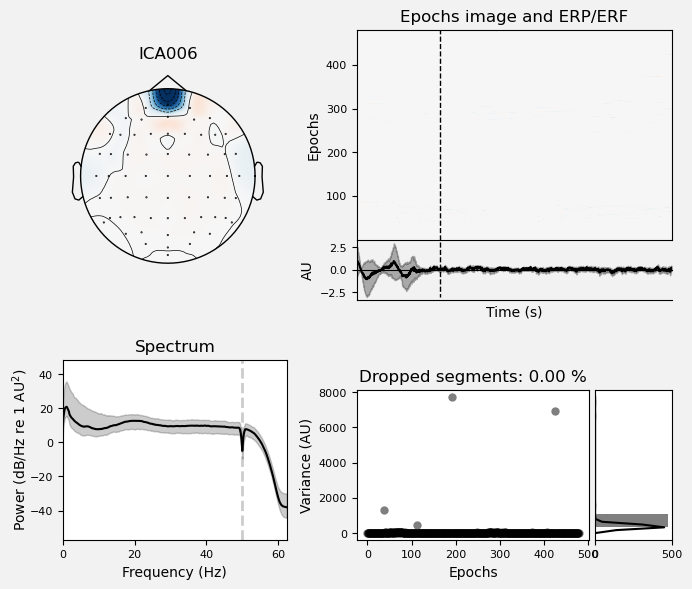

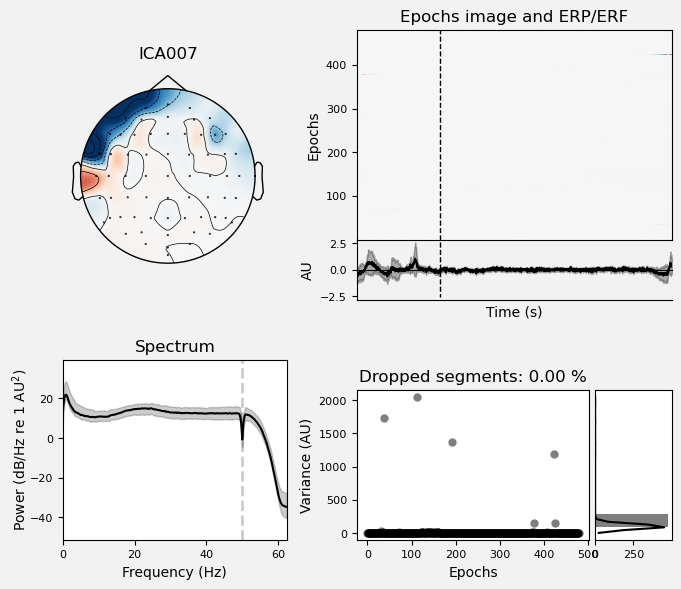

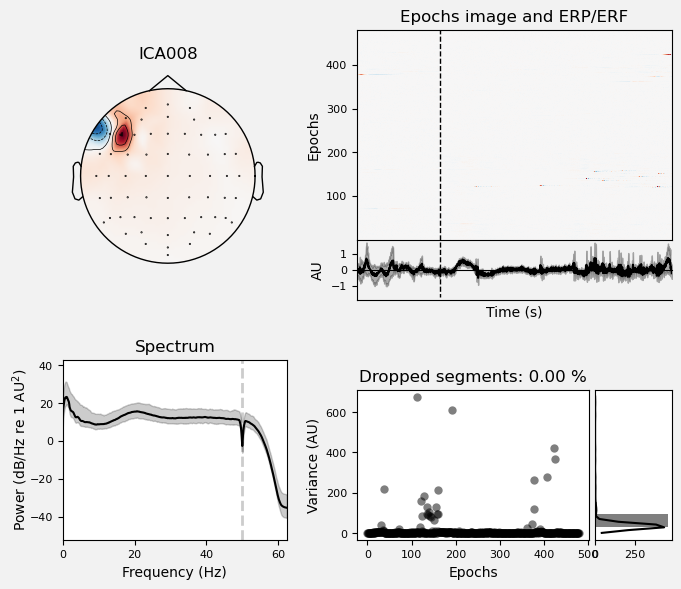

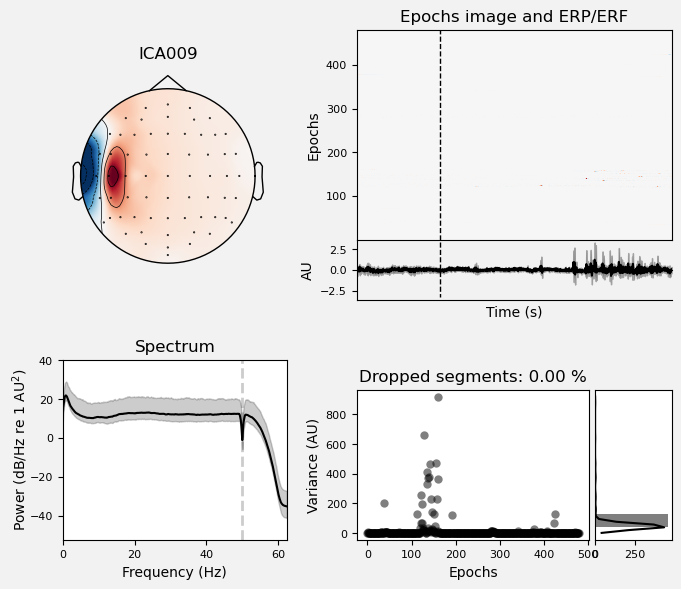

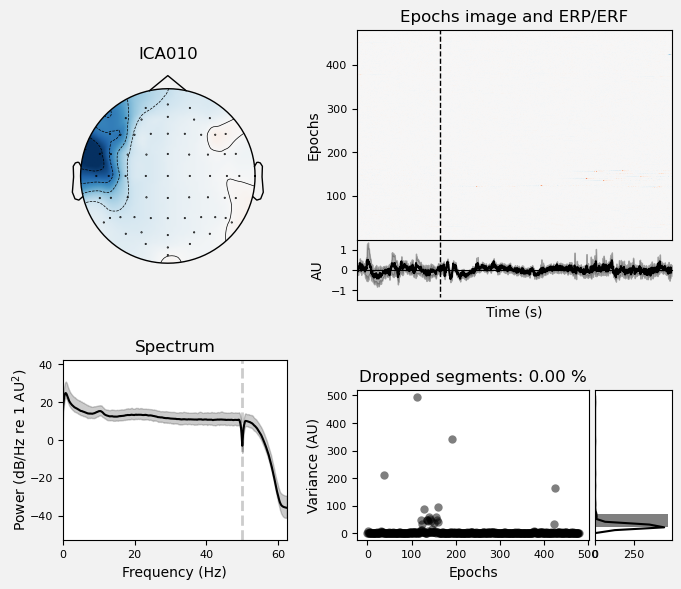

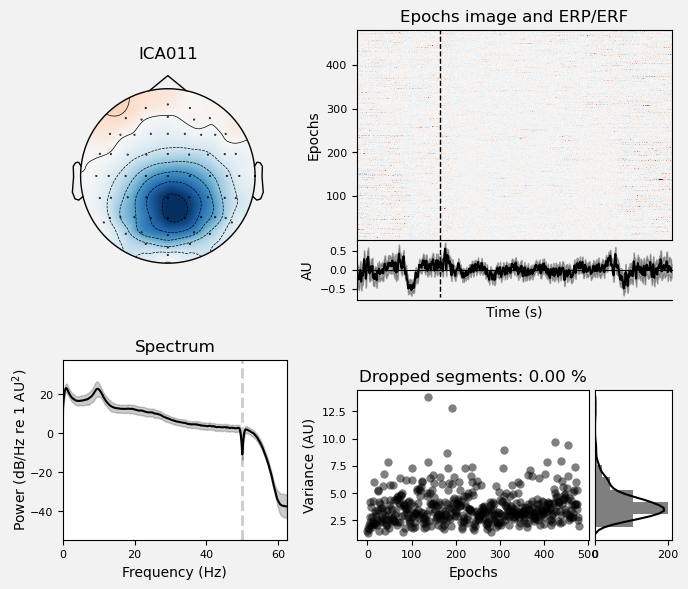

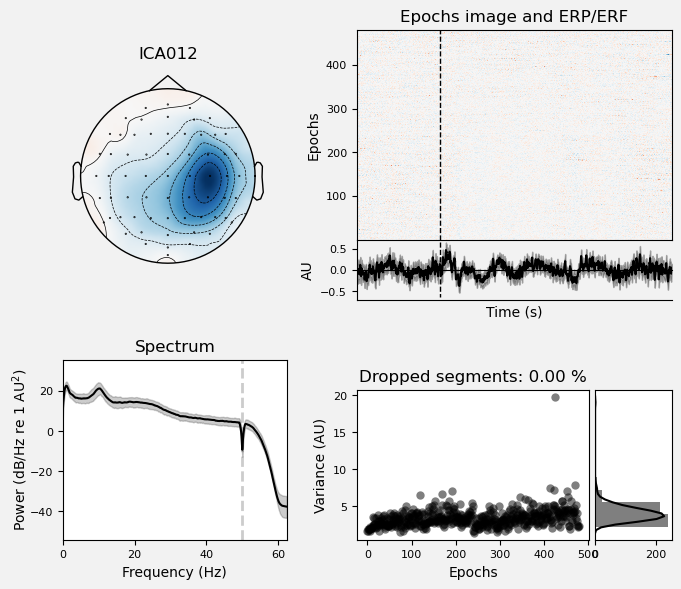

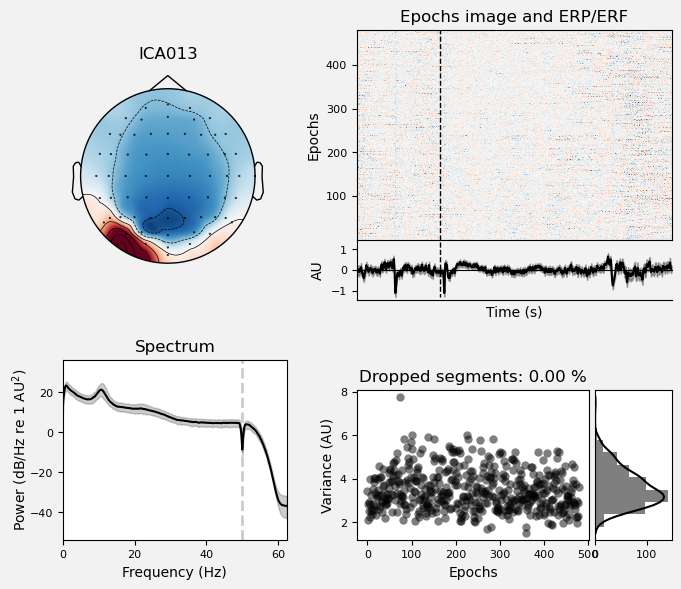

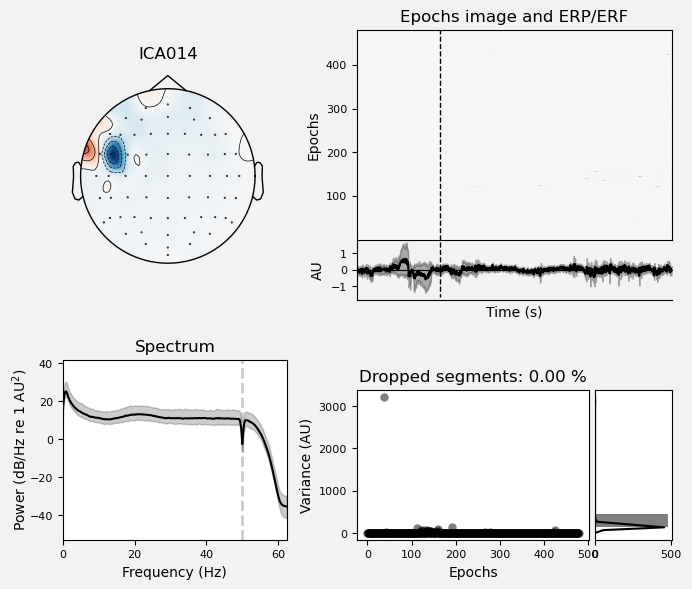

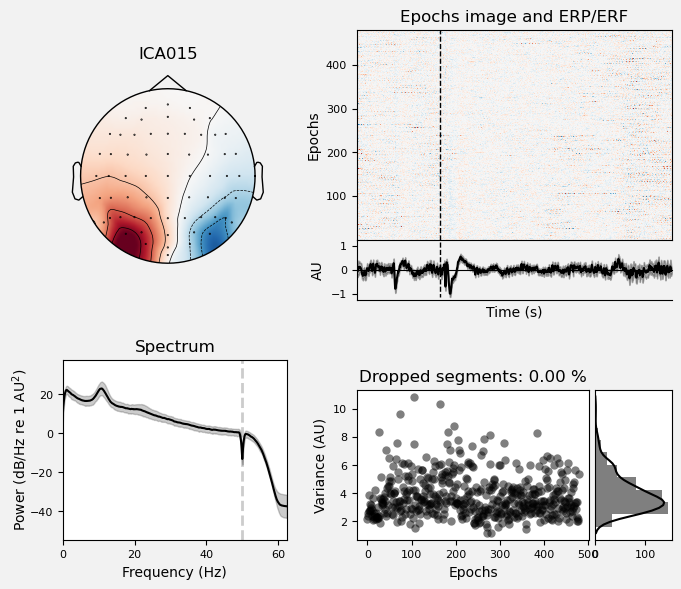

In [13]:
ica.plot_properties(All_Epochs_for_ICA, picks=[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15])
plt.show()

In [14]:
explained_var_ratio = ica.get_explained_variance_ratio(All_Epochs_for_ICA)
explained_var_ratio

{'eeg': np.float64(1.0)}

    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 pro

c:\Users\pipo_\miniconda3\envs\MTP_project\Lib\site-packages\mne\viz\ica.py:188: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=figsize, facecolor=[0.95] * 3)


Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated


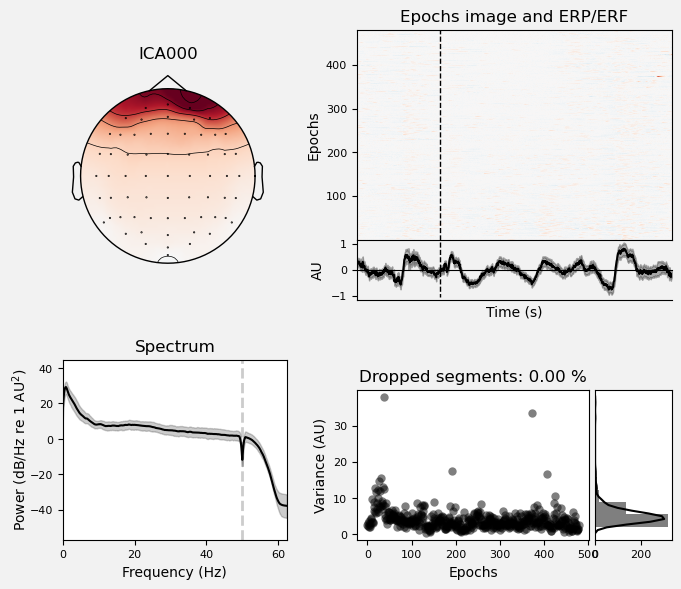

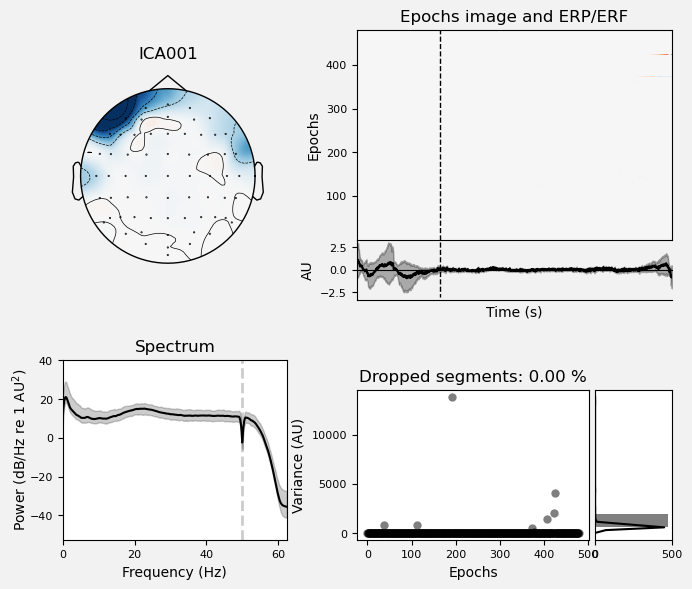

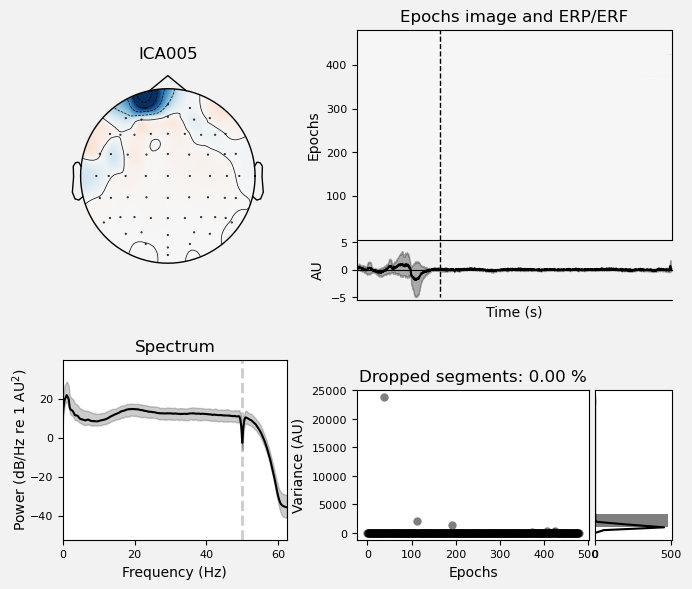

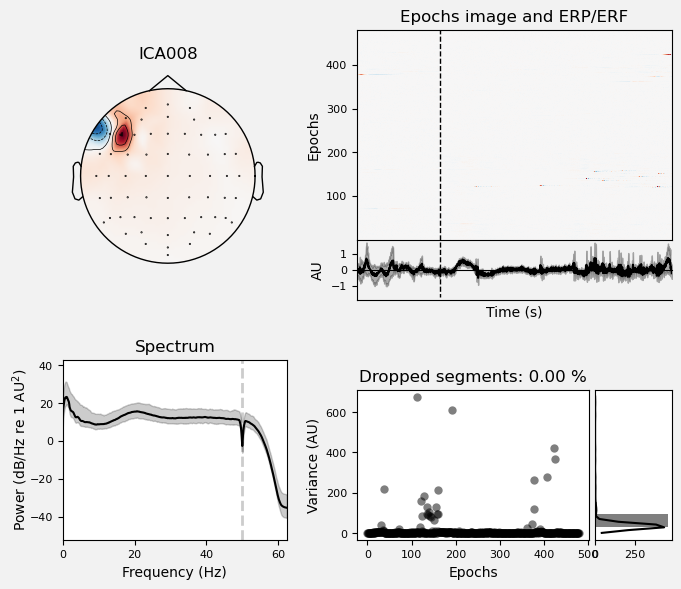

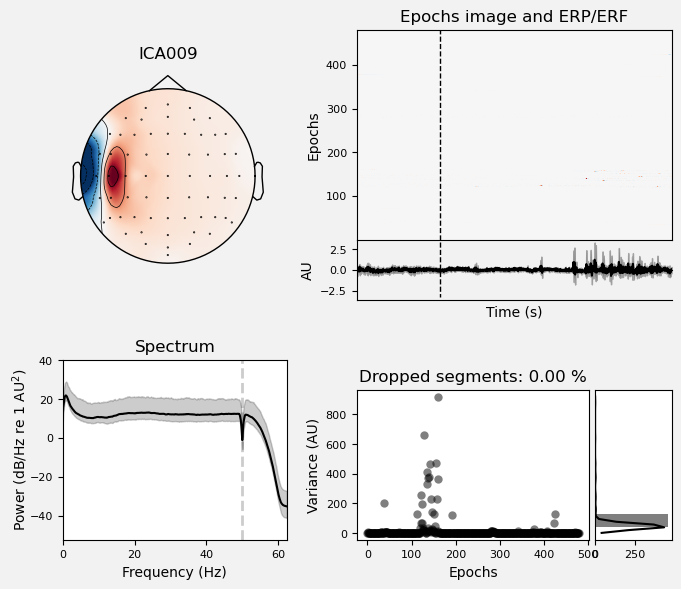

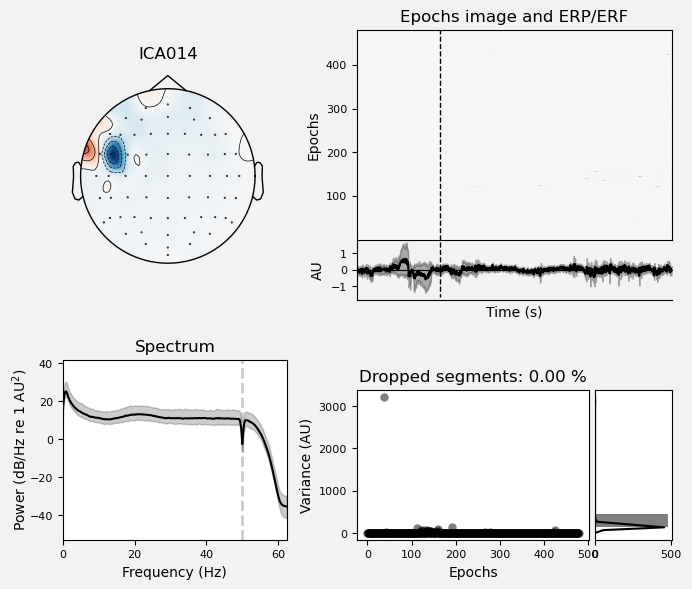

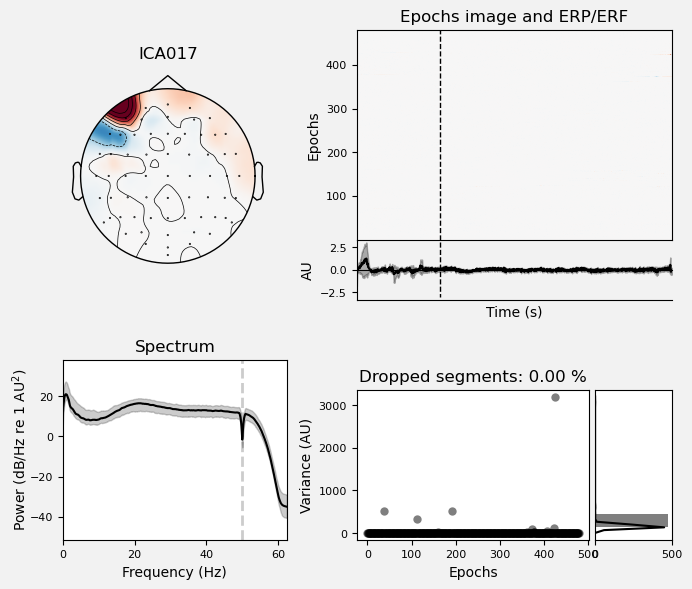

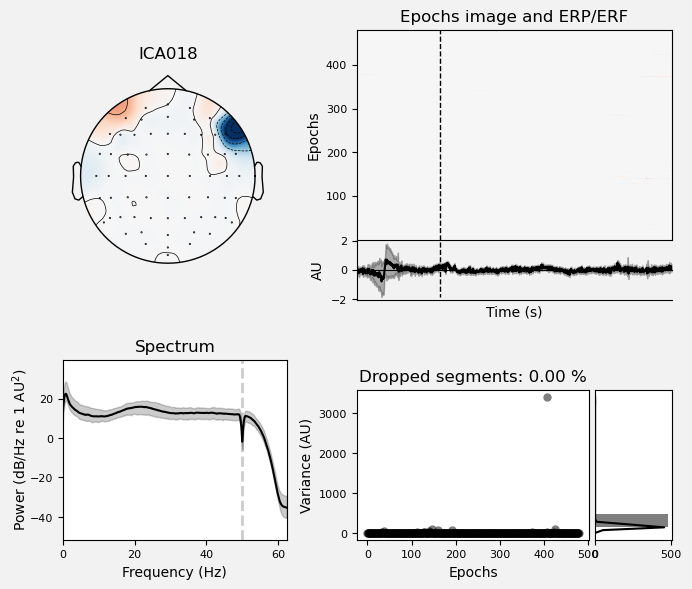

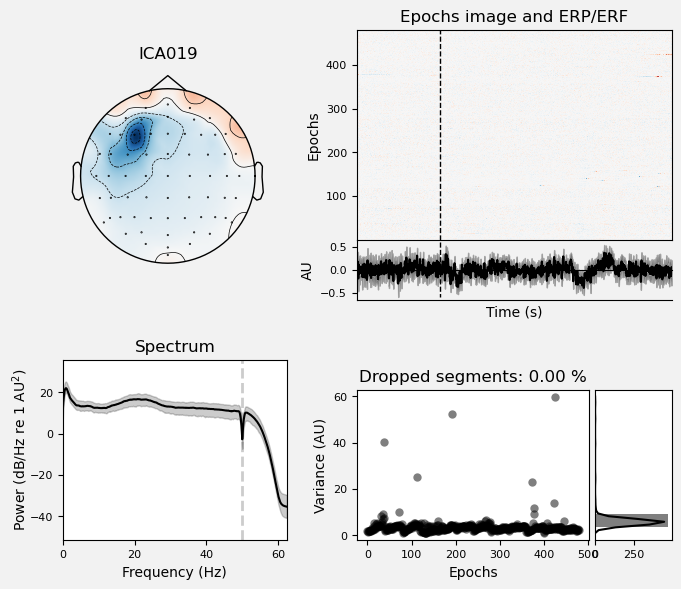

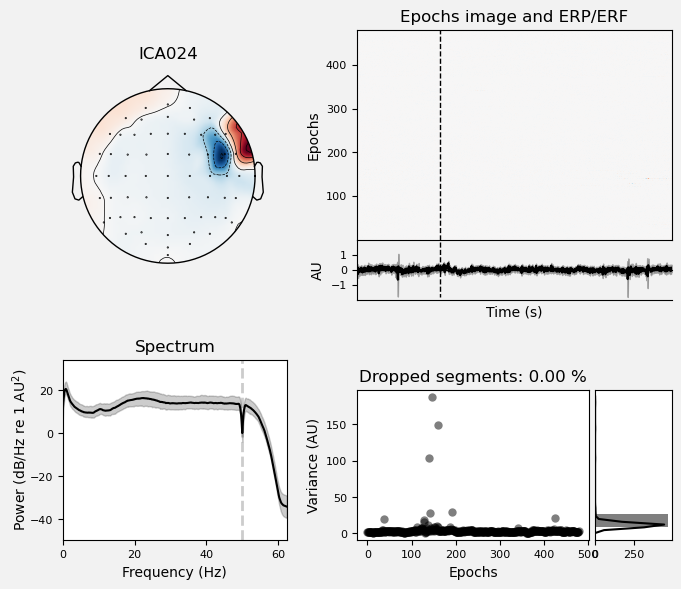

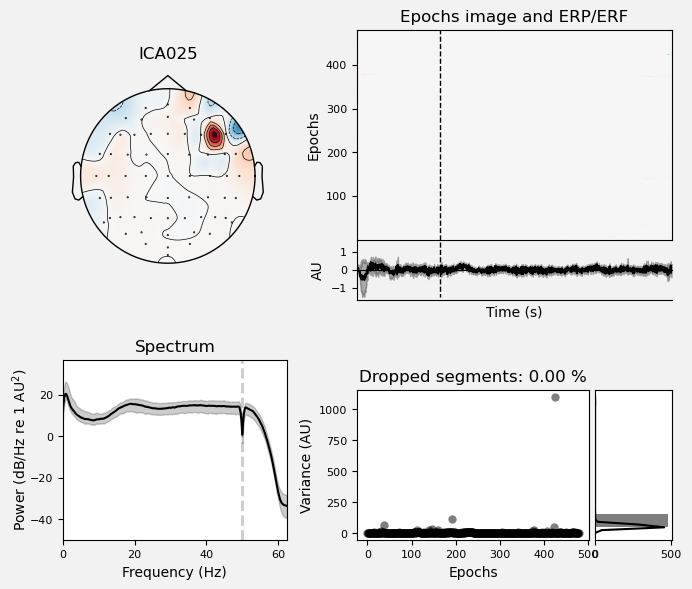

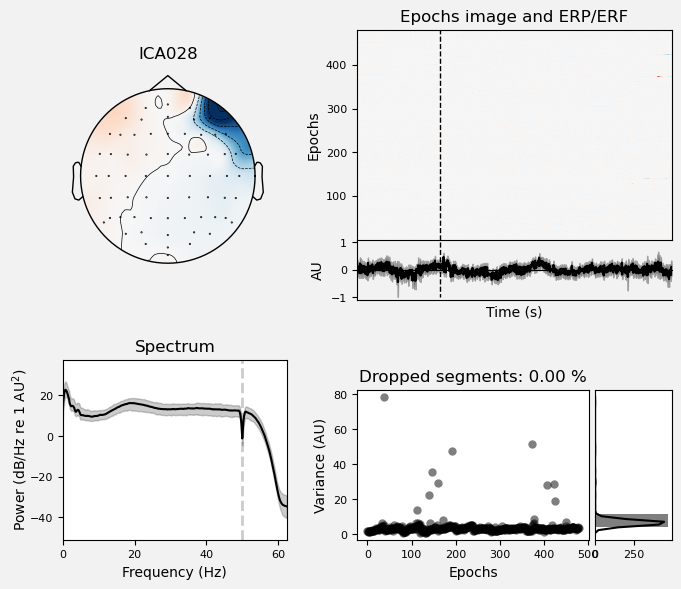

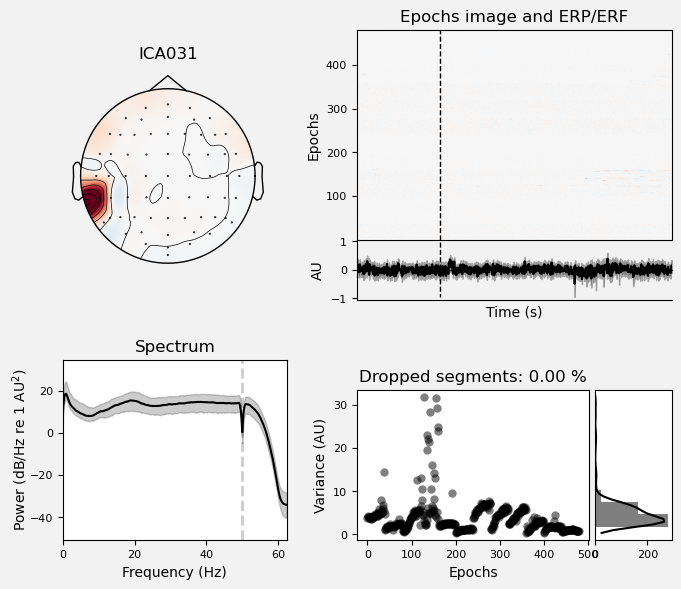

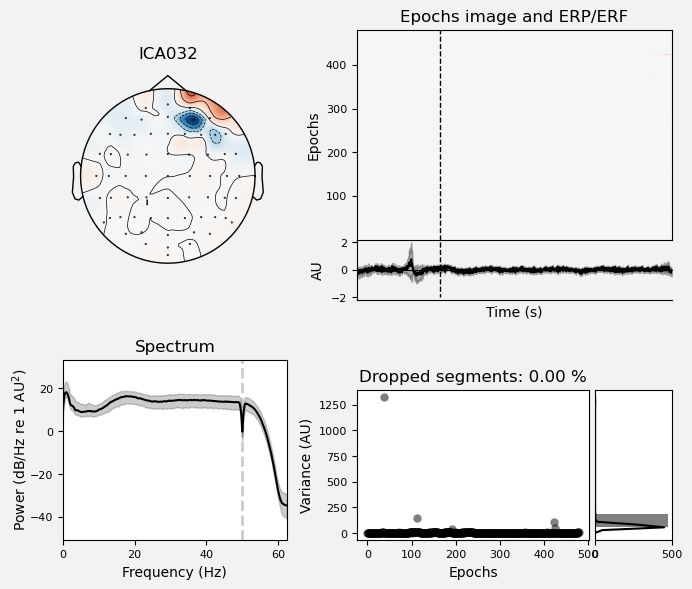

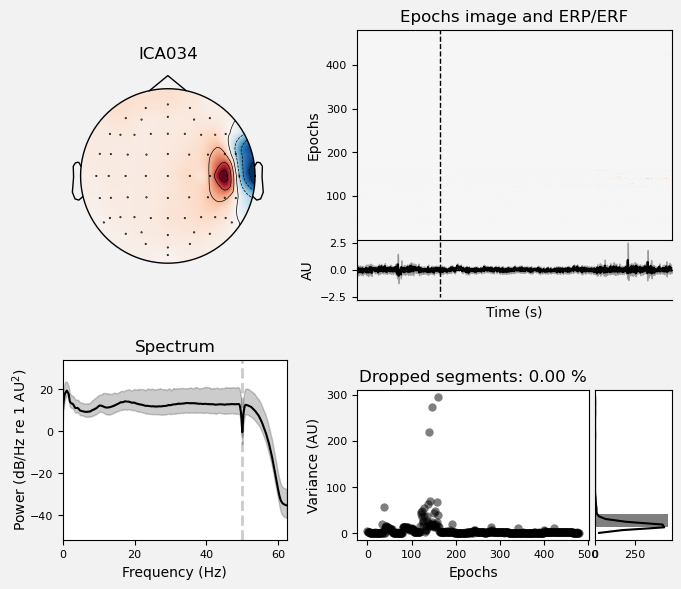

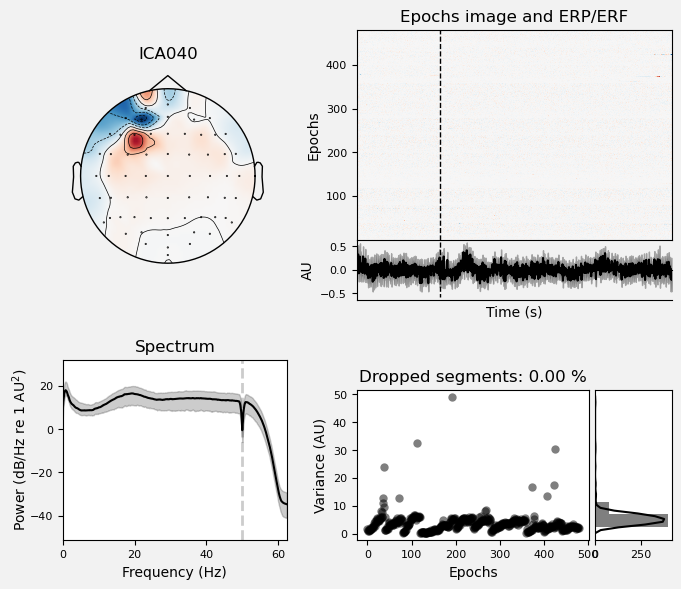

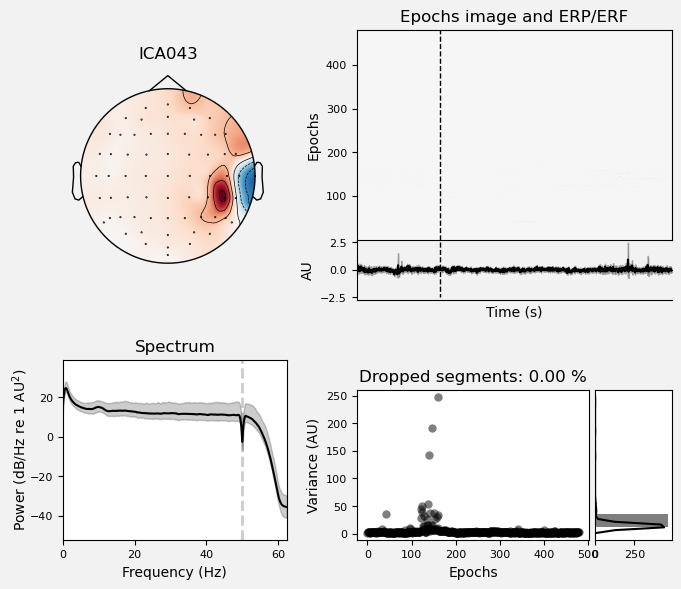

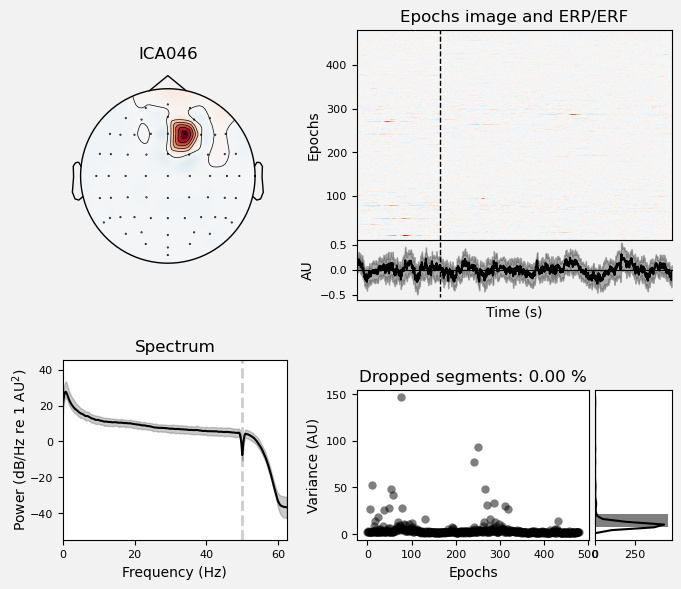

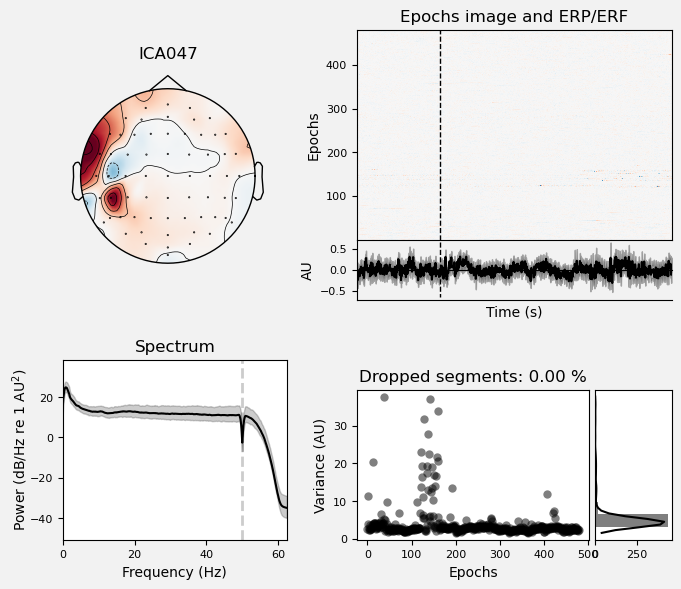

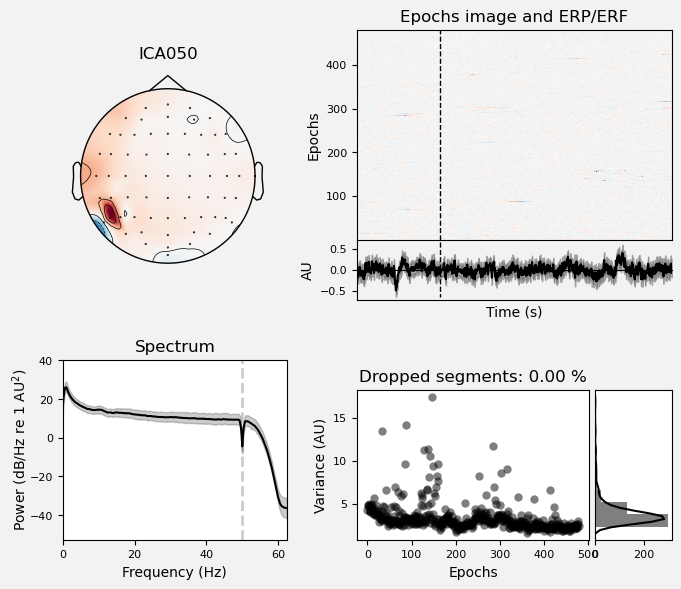

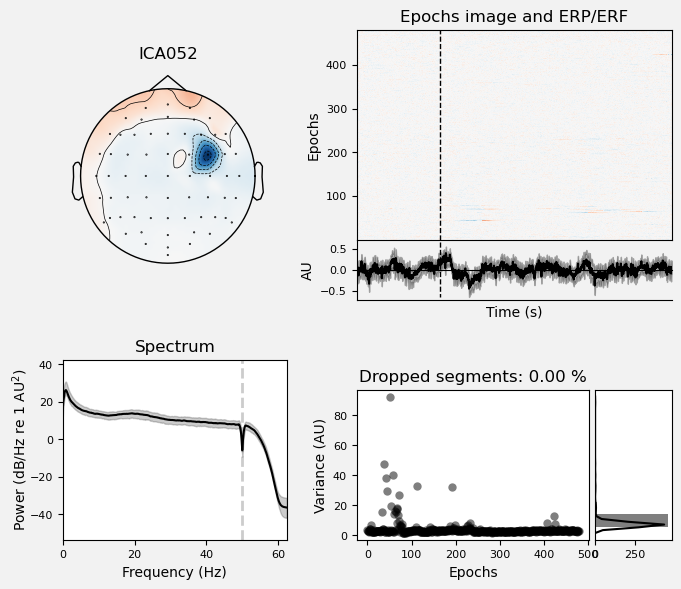

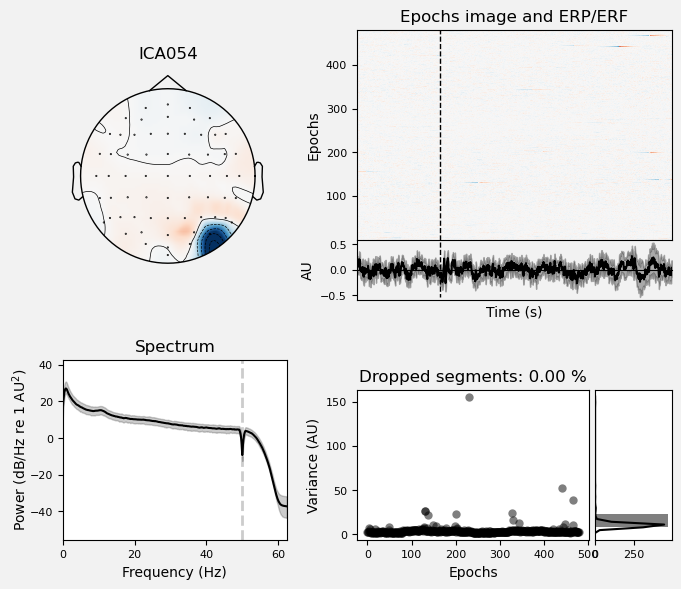

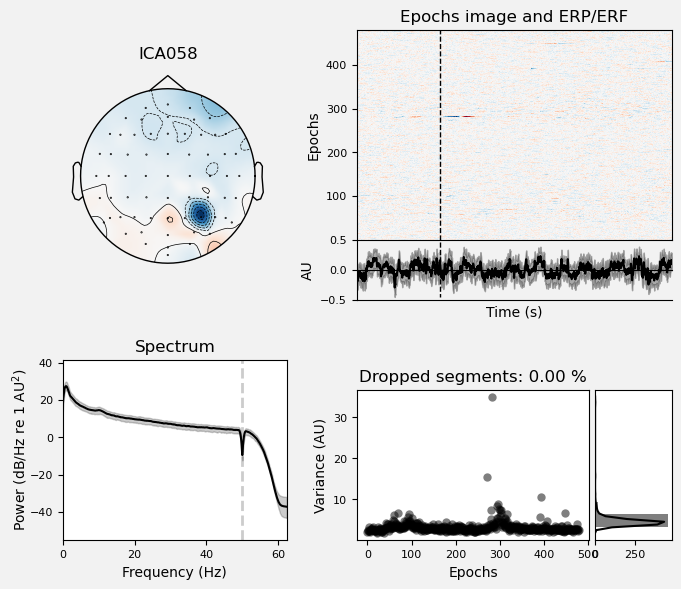

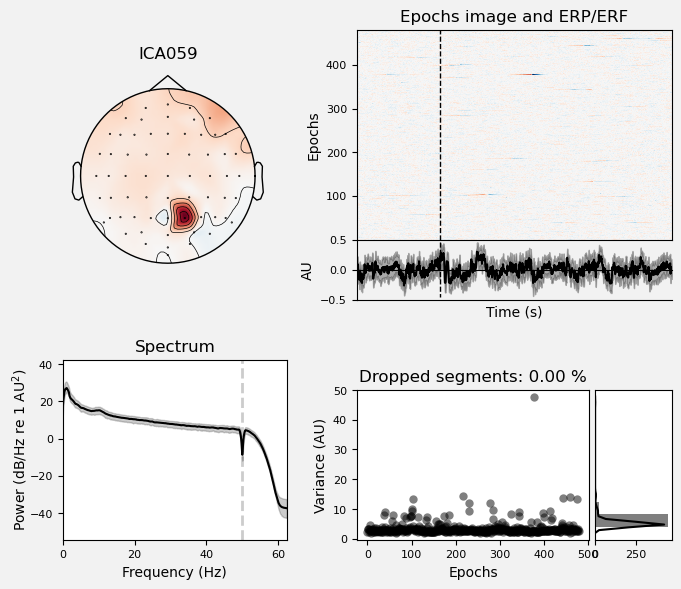

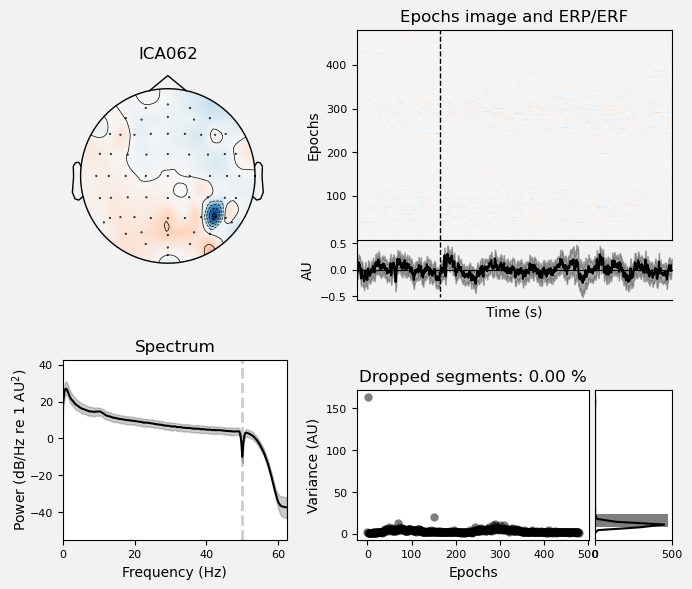

In [15]:
ica.plot_properties(All_Epochs_for_ICA, picks=exclude_idx)
plt.show()

In [16]:
print(exclude_idx)

[0, 1, 5, 8, 9, 14, 17, 18, 19, 24, 25, 28, 31, 32, 34, 40, 43, 46, 47, 50, 52, 54, 58, 59, 62]


In [17]:
ica.plot_sources(All_Epochs_for_ICA, show_scrollbars=False)
print("...")

Not setting metadata
480 matching events found
No baseline correction applied
0 projection items activated
Using qt as 2D backend.
...


In [18]:
choose

NameError: name 'choose' is not defined

In [19]:
ICA_cleaned = ica.apply(All_Epochs, exclude= exclude_idx)

Applying ICA to Epochs instance
    Transforming to ICA space (64 components)
    Zeroing out 25 ICA components
    Projecting back using 64 PCA components


In [ ]:
ICA_cleaned.plot(title='ICA cleaned data')

Dropped 0 epochs: 
The following epochs were marked as bad and are dropped:
[]
Channels marked as bad:
none


In [ ]:
ICA_cleaned

<EpochsArray | 480 events (all good), -0.5 – 5 s (baseline off), ~660.3 MiB, data loaded,
 'Number 1': 120
 'Number 2': 120
 'Number 3': 120
 'Number 4': 120>

# Save cleaned data

In [21]:
ICA_cleaned.save(f"D:\\MTP_task\\MTP_eeg\\cleaned_data\\ICA_cleaned_Epoch_{subject}.fif", overwrite=True)

Overwriting existing file.


C:\Users\pipo_\AppData\Local\Temp\ipykernel_26356\2007307936.py:1: RuntimeWarning: This filename (D:\MTP_task\MTP_eeg\cleaned_data\ICA_cleaned_Epoch_s009.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  ICA_cleaned.save(f"D:\\MTP_task\\MTP_eeg\\cleaned_data\\ICA_cleaned_Epoch_{subject}.fif", overwrite=True)


Overwriting existing file.
Overwriting existing file.


[WindowsPath('D:/MTP_task/MTP_eeg/cleaned_data/ICA_cleaned_Epoch_s009.fif')]